# Diabetes Risk Factor Analysis
**Author:** Mohammad Mustafa Arghand

A beginner data science project exploring the **Pima Indians Diabetes Dataset** — a classic, publicly available medical dataset of 768 patients. I chose this topic because of my background working in a pharmacy (CVS), where I regularly see how health data connects to patient outcomes.

**Goal:** explore which health measurements are most associated with a diabetes diagnosis, using Python, pandas, and basic data visualization.

**Dataset source:** Originally from the National Institute of Diabetes and Digestive and Kidney Diseases, widely used as a beginner-friendly dataset (UCI Machine Learning Repository / Kaggle).


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
print("Libraries loaded successfully.")


Libraries loaded successfully.


## 2. Load the Data

Each row is one patient. Columns include number of pregnancies, glucose level, blood pressure, skin thickness, insulin, BMI, a diabetes pedigree score (family history), age, and the outcome (1 = diabetic, 0 = not diabetic).

In [2]:
df = pd.read_csv("diabetes.csv")
print("Shape of dataset (rows, columns):", df.shape)
df.head()


Shape of dataset (rows, columns): (768, 9)


In [3]:
print(df.head().to_string())


   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  DiabetesPedigreeFunction  Age  Outcome
0            6      148             72             35        0  33.6                     0.627   50        1
1            1       85             66             29        0  26.6                     0.351   31        0
2            8      183             64              0        0  23.3                     0.672   32        1
3            1       89             66             23       94  28.1                     0.167   21        0
4            0      137             40             35      168  43.1                     2.288   33        1


## 3. Clean the Data

This dataset has a quirk common in real health data: missing values were recorded as **0** instead of being left blank. A blood pressure or BMI of 0 isn't medically possible, so those zeros actually mean "not recorded." I replaced them with `NaN` so they don't distort the analysis (e.g., dragging down the average BMI).

In [4]:
cols_with_invalid_zero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols_with_invalid_zero] = df[cols_with_invalid_zero].replace(0, np.nan)

missing_counts = df[cols_with_invalid_zero].isna().sum()
print("Missing values per column after fixing the zero-encoding issue:")
print(missing_counts.to_string())


Missing values per column after fixing the zero-encoding issue:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11


## 4. Question 1 — Does average glucose differ between diabetic and non-diabetic patients?

In [5]:
avg_glucose = df.groupby("Outcome")["Glucose"].mean().round(1)
print("Average glucose level by outcome (0 = non-diabetic, 1 = diabetic):")
print(avg_glucose.to_string())


Average glucose level by outcome (0 = non-diabetic, 1 = diabetic):
Outcome
0    110.6
1    142.3


## 5. Question 2 — Which health measurements correlate most with diabetes?

Correlation measures how strongly two variables move together, from -1 to 1. Values closer to 1 (or -1) mean a stronger relationship. I'm checking which columns correlate most with the `Outcome` column.

In [6]:
correlations = df.corr(numeric_only=True)["Outcome"].drop("Outcome").sort_values(ascending=False)
print("Correlation of each measurement with diabetes outcome (highest first):")
print(correlations.round(3).to_string())


Correlation of each measurement with diabetes outcome (highest first):
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171


## 6. Visualization — Glucose Distribution by Outcome

A boxplot makes it easy to see at a glance that diabetic patients tend to have higher glucose readings, and by how much.

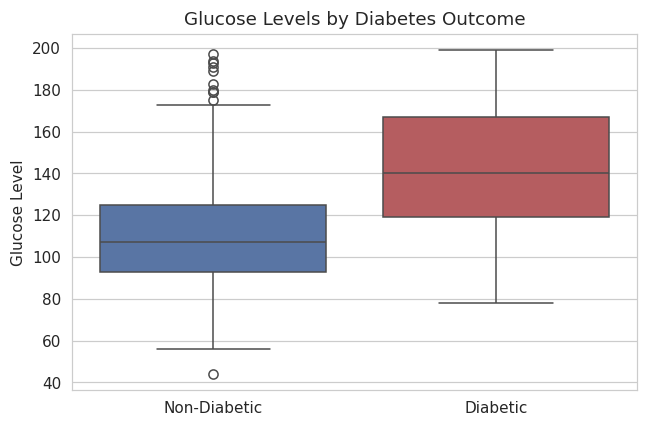

In [7]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="Outcome", y="Glucose", hue="Outcome", palette=["#4C72B0", "#C44E52"], legend=False)
plt.xticks([0, 1], ["Non-Diabetic", "Diabetic"])
plt.title("Glucose Levels by Diabetes Outcome")
plt.xlabel("")
plt.ylabel("Glucose Level")
plt.tight_layout()


## 7. Visualization — Correlation Heatmap

This heatmap shows how every measurement relates to every other measurement, including the outcome. Darker/warmer colors mean a stronger relationship.

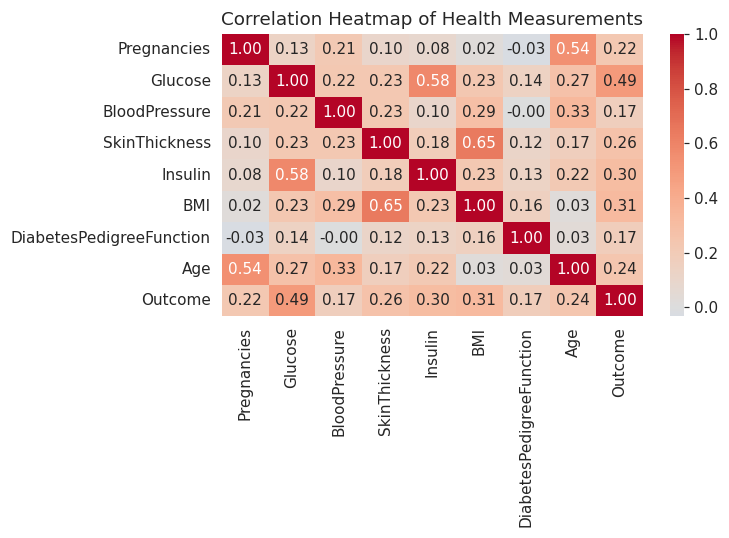

In [8]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Health Measurements")
plt.tight_layout()


## 8. Summary of Findings

- **Glucose level** has the strongest relationship with a diabetes diagnosis of all the measurements in this dataset — diabetic patients had a noticeably higher average glucose reading than non-diabetic patients.
- **BMI** and **Age** also showed a meaningful positive relationship with diabetes outcome, consistent with known real-world risk factors.
- **Blood pressure** had the weakest relationship with outcome among the measurements tested here.
- A real-world data quirk (zeros used to mean "missing") had to be corrected before any of these numbers could be trusted — a reminder that most of the real work in data analysis is cleaning the data *before* drawing conclusions.

**Note:** This is an educational exploratory analysis, not a medical diagnostic tool. The patterns above describe this specific historical dataset, not medical advice for any individual.

**Tools used:** Python, pandas, NumPy, matplotlib, seaborn (via Google Colab)
